In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import scipy.stats as stats
import warnings
warnings.filterwarnings('ignore')


sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

In [3]:
customer_info = pd.read_csv('../raw_data/segmentation_data.csv')
print(f'Dataset shape: {customer_info.shape[0]} rows, {customer_info.shape[1]} columns')
customer_info.head(10)

Dataset shape: 2000 rows, 8 columns


,ID,Sex,Marital status,Age,Education,Income,Occupation,Settlement size
0,100000001,0,0,67,2,124670,1,2
1,100000002,1,1,22,1,150773,1,2
2,100000003,0,0,49,1,89210,0,0
3,100000004,0,0,45,1,171565,1,1
4,100000005,0,0,53,1,149031,1,1
5,100000006,0,0,35,1,144848,0,0
6,100000007,0,0,53,1,156495,1,1
7,100000008,0,0,35,1,193621,2,1
8,100000009,0,1,61,2,151591,0,0
9,100000010,0,1,28,1,174646,2,0


In [4]:
customer_info.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   ID               2000 non-null   int64
 1   Sex              2000 non-null   int64
 2   Marital status   2000 non-null   int64
 3   Age              2000 non-null   int64
 4   Education        2000 non-null   int64
 5   Income           2000 non-null   int64
 6   Occupation       2000 non-null   int64
 7   Settlement size  2000 non-null   int64
dtypes: int64(8)
memory usage: 125.1 KB


In [5]:
customer_info.describe()

,ID,Sex,Marital status,Age,Education,Income,Occupation,Settlement size
count,2.000000e+03,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000
mean,1.000010e+08,0.457000,0.496500,35.909000,1.03800,120954.419000,0.810500,0.739000
std,5.774946e+02,0.498272,0.500113,11.719402,0.59978,38108.824679,0.638587,0.812533
min,1.000000e+08,0.000000,0.000000,18.000000,0.00000,35832.000000,0.000000,0.000000
25%,1.000005e+08,0.000000,0.000000,27.000000,1.00000,97663.250000,0.000000,0.000000
50%,1.000010e+08,0.000000,0.000000,33.000000,1.00000,115548.500000,1.000000,1.000000
75%,1.000015e+08,1.000000,1.000000,42.000000,1.00000,138072.250000,1.000000,1.000000
max,1.000020e+08,1.000000,1.000000,76.000000,3.00000,309364.000000,2.000000,2.000000


In [11]:
missing_value = customer_info.isnull().sum()
duplicate_value = customer_info.duplicated().sum()

print(f'Missing Value : \n{missing_value} \n\nDuplicated Value : {duplicate_value}')

Missing Value : 
ID                 0
Sex                0
Marital status     0
Age                0
Education          0
Income             0
Occupation         0
Settlement size    0
dtype: int64 

Duplicated Value : 0


### Column Descriptions

| Column | Type | Meaning |
|--------|------|---------|
| ID | - | Unique customer identifier (will be dropped) |
| Sex | Categorical | 0 = Male, 1 = Female |
| Marital status | Categorical | 0 = Single, 1 = Non-single (married/partner) |
| Age | Numerical | Customer age in years |
| Education | Ordinal | 0 = Other/Unknown, 1 = High School, 2 = University, 3 = Graduate |
| Income | Numerical | Annual income |
| Occupation | Ordinal | 0 = Unemployed/Unskilled, 1 = Skilled/Official, 2 = Management/Self-employed |
| Settlement size | Ordinal | 0 = Small city, 1 = Mid-size city, 2 = Big city |

In [13]:
customer_info = customer_info.drop(columns='ID')

cat_cols = ['Sex','Marital status','Education','Occupation','Settlement size']
num_cols = ['Age','Income']

---
## 2. Exploratory Data Analysis (EDA)

Before clustering, we need to understand each feature's distribution and how features relate to each other. This helps us spot outliers, skew, and natural groupings.

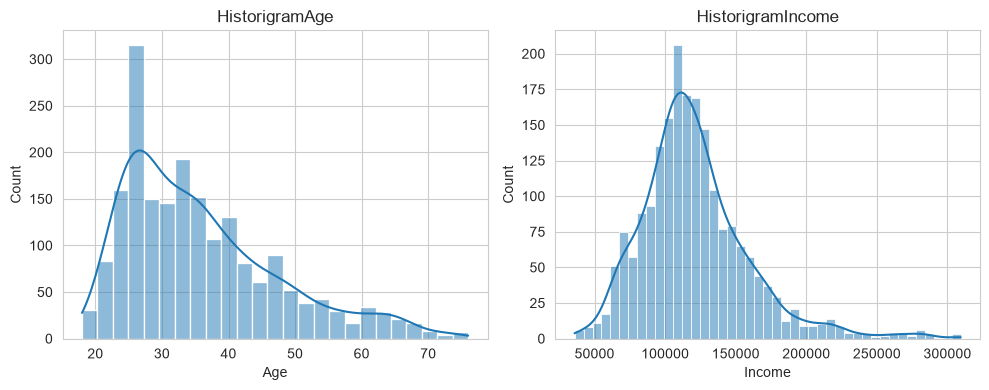

In [18]:
fig,axe = plt.subplots(1,2,figsize=(10,4))
for i, col in enumerate(num_cols):
    sns.histplot(data=customer_info,x=col,kde=True, ax=axe[i])
    axe[i].set_title(f"Historigram{col}")
    
plt.tight_layout()
plt.show()

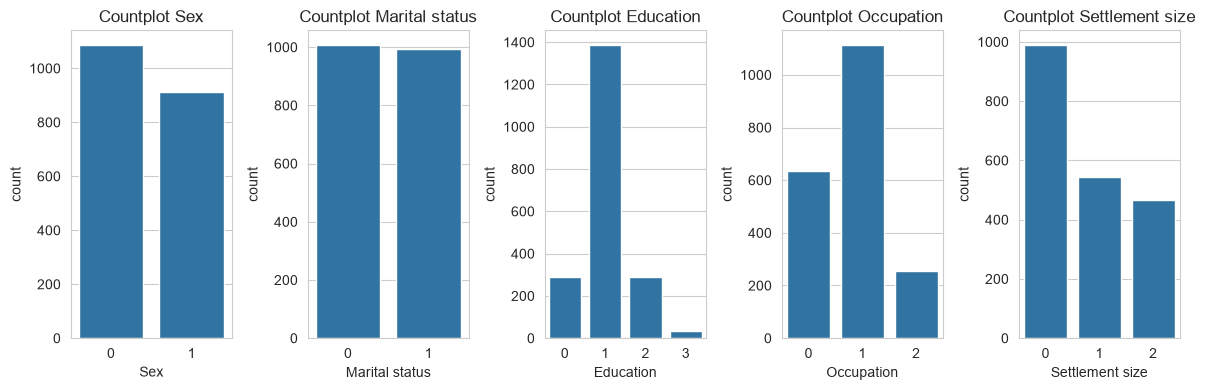

In [23]:
fig,axe = plt.subplots(1,len(cat_cols),figsize=(12,4))
for i, col in enumerate(cat_cols):
    sns.countplot(data=customer_info,x=col, ax=axe[i])
    axe[i].set_title(f'Countplot {col}')
    
plt.tight_layout()
plt.show()

Correlation : 0.341,
p-value : 1.64e-55


Text(0.5, 1.0, 'Correlation Age & Income = 0.341')

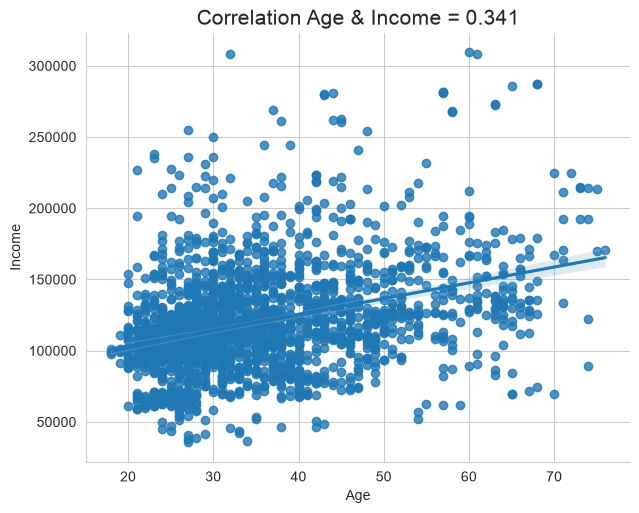

In [33]:
corr_val , p_val = stats.pearsonr(customer_info['Age'],customer_info['Income'])
print(f'Correlation : {corr_val:.3f},\np-value : {p_val:.2e}')

sns.lmplot(customer_info, x='Age',y='Income', aspect=1.3)
plt.title(f'Correlation Age & Income = {corr_val:.3f}',fontsize=15)

**Interpretation:** Correlation of ~0.34 is weak-to-moderate. Older customers tend to earn slightly more, but age alone doesn't determine income.

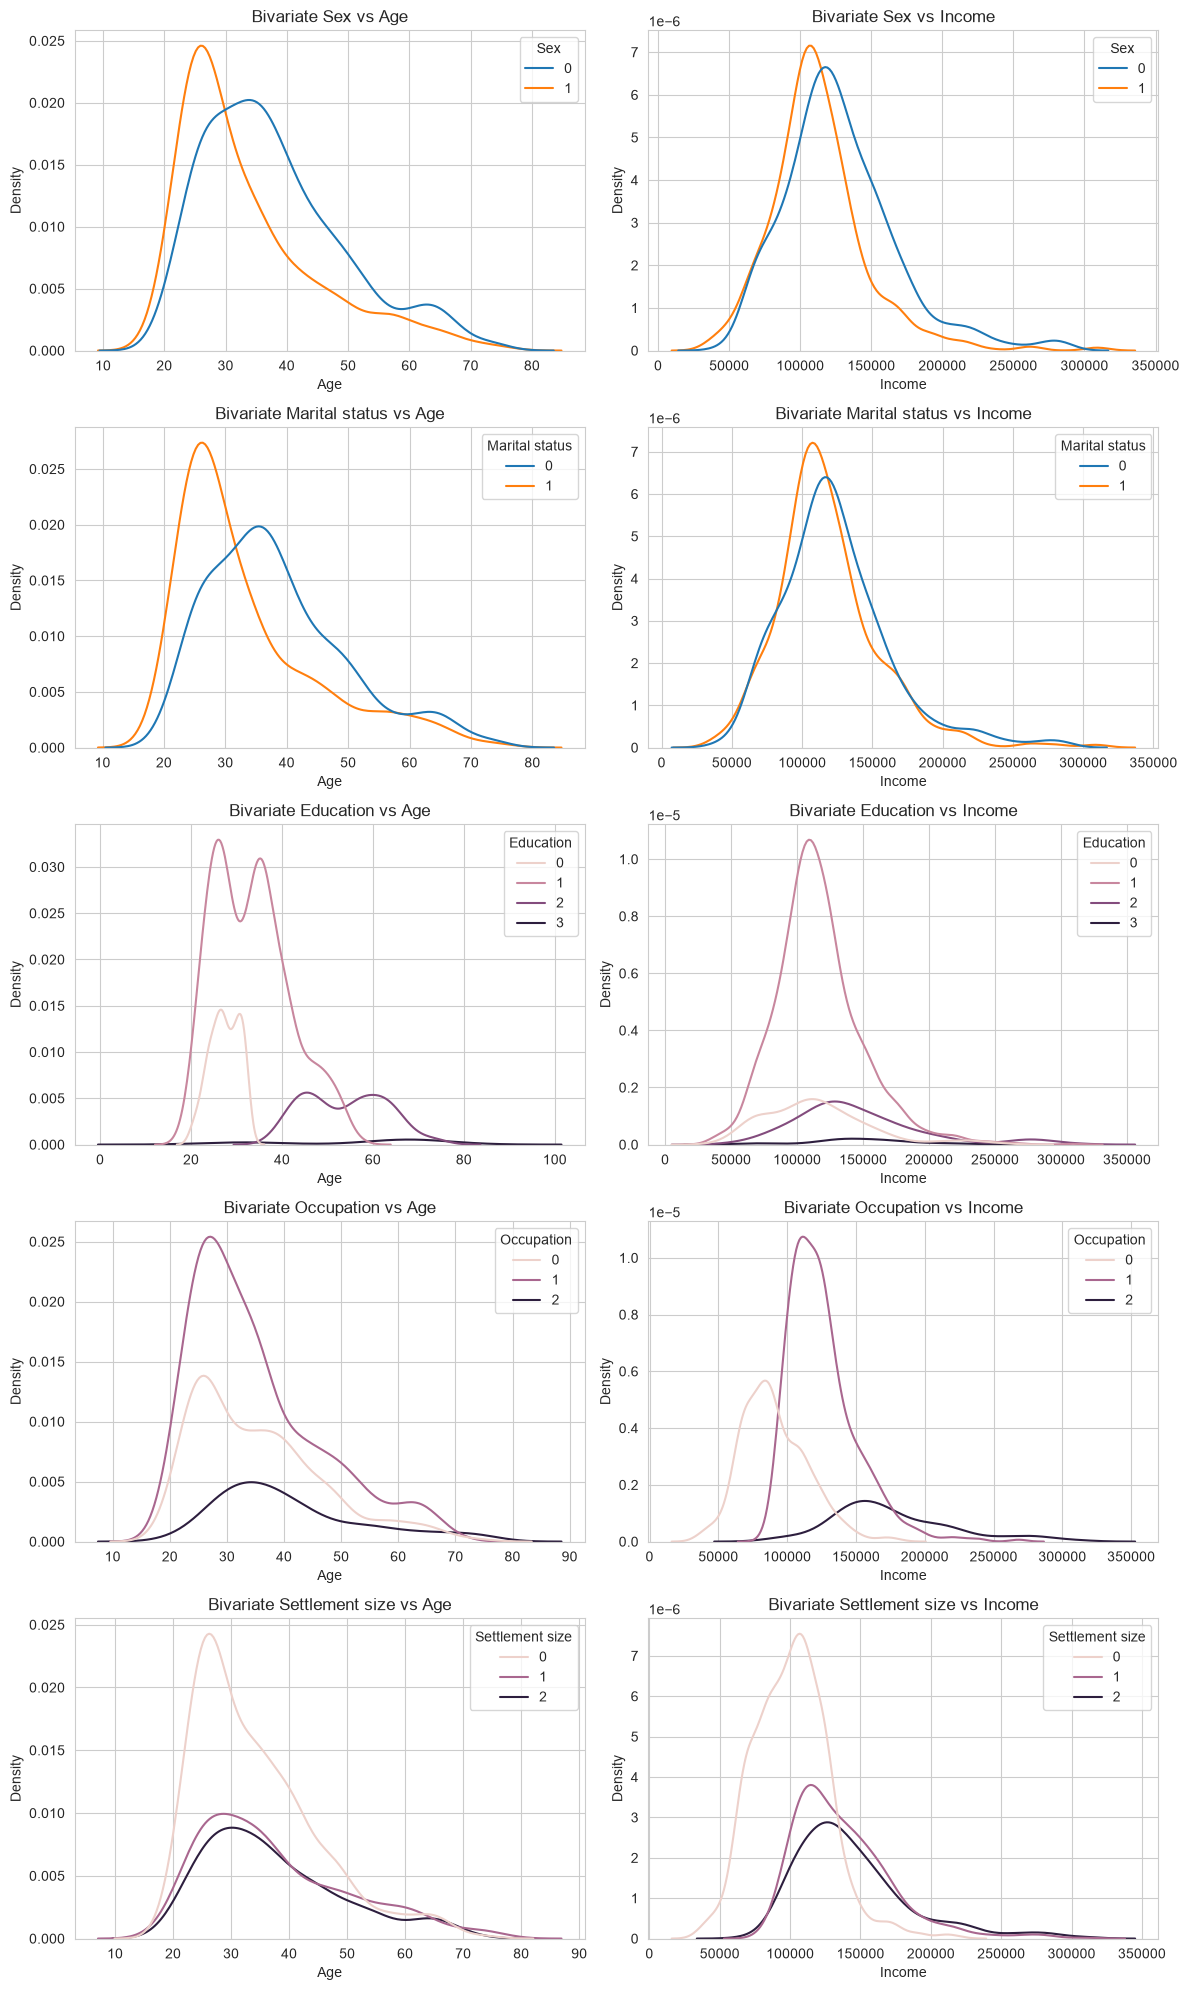

In [37]:
fig,axe = plt.subplots(len(cat_cols),2,figsize=(12,4 * len(cat_cols)))
for i , cat in enumerate(cat_cols):
    for j,num in enumerate(num_cols):
        sns.kdeplot(data=customer_info , x=num, hue=cat , ax=axe[i][j])
        axe[i][j].set_title(f"Bivariate {cat} vs {num}")
        
plt.tight_layout()

In [38]:
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(customer_info)

print(f'Scaled data shape: {X_scaled.shape}')
print(f'Min values after scaling: {X_scaled.min(axis=0)}')
print(f'Max values after scaling: {X_scaled.max(axis=0)}')

Scaled data shape: (2000, 7)
Min values after scaling: [0. 0. 0. 0. 0. 0. 0.]
Max values after scaling: [1. 1. 1. 1. 1. 1. 1.]


In [39]:
pca = PCA(n_components=3, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# How much information did we keep?
explained = pca.explained_variance_ratio_
total_explained = explained.sum()

print('Explained variance per component:')
for i, var in enumerate(explained):
    print(f'  PC{i+1}: {var:.3f} ({var*100:.1f}%)')
print(f'\nTotal variance retained: {total_explained:.3f} ({total_explained*100:.1f}%)')

if total_explained < 0.70:
    print('\nLess than 70% variance retained — clusters may lose important structure.')
    print('   Consider using more components or clustering on the full scaled data.')
else:
    print(f'\n✓ {total_explained*100:.1f}% is a reasonable amount of information to keep.')

Explained variance per component:
  PC1: 0.483 (48.3%)
  PC2: 0.248 (24.8%)
  PC3: 0.112 (11.2%)

Total variance retained: 0.844 (84.4%)

✓ 84.4% is a reasonable amount of information to keep.


<Axes: >

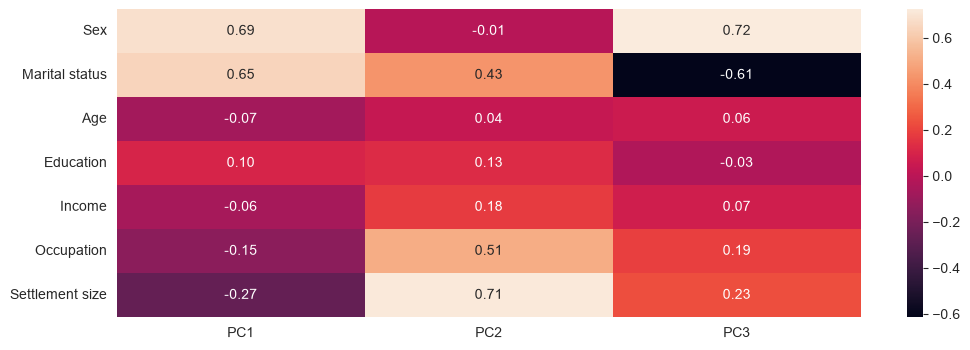

In [41]:
pca_loading = pd.DataFrame(
    pca.components_.T,
    columns=['PC1','PC2','PC3'],
    index=customer_info.columns
)

plt.figure(figsize=(12,4))
sns.heatmap(pca_loading, annot=True, fmt='.2f')

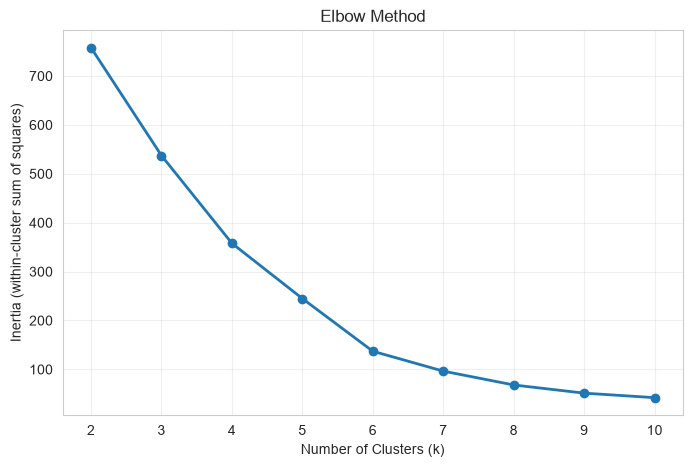

In [42]:
cluster_range = range(2, 11)
inertias = []

for k in cluster_range:
    km = KMeans(n_clusters=k, random_state=42, init='k-means++', n_init=10)
    km.fit(X_pca)  # <-- Clustering on PCA data (same data we'll use later)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(cluster_range), inertias, marker='o', linewidth=2)
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (within-cluster sum of squares)')
plt.title('Elbow Method')
plt.xticks(list(cluster_range))
plt.grid(True, alpha=0.3)
plt.show()

In [43]:
cluster_range = range(2, 11)
seed_range = range(0, 18)
results = []

for k in cluster_range:
    for seed in seed_range:
        km = KMeans(n_clusters=k, random_state=seed, init='k-means++', n_init=10)
        labels = km.fit_predict(X_pca)  # <-- Same PCA data
        score = silhouette_score(X_pca, labels)
        results.append({'n_clusters': k, 'seed': seed, 'silhouette_score': score})

results_df = pd.DataFrame(results)

# Show the average silhouette score for each k
avg_scores = results_df.groupby('n_clusters')['silhouette_score'].agg(['mean', 'std'])
avg_scores.columns = ['Mean Silhouette', 'Std']
print('Average Silhouette Score per Cluster Count:')
print(avg_scores.round(4))
print(f'\nBest k by mean silhouette: {avg_scores["Mean Silhouette"].idxmax()}')

Average Silhouette Score per Cluster Count:
            Mean Silhouette     Std
n_clusters                         
2                    0.4797  0.0034
3                    0.4798  0.0005
4                    0.5541  0.0194
5                    0.6211  0.0000
6                    0.6756  0.0000
7                    0.6962  0.0000
8                    0.6990  0.0001
9                    0.7025  0.0000
10                   0.7403  0.0042

Best k by mean silhouette: 10


<Axes: xlabel='seed', ylabel='n_clusters'>

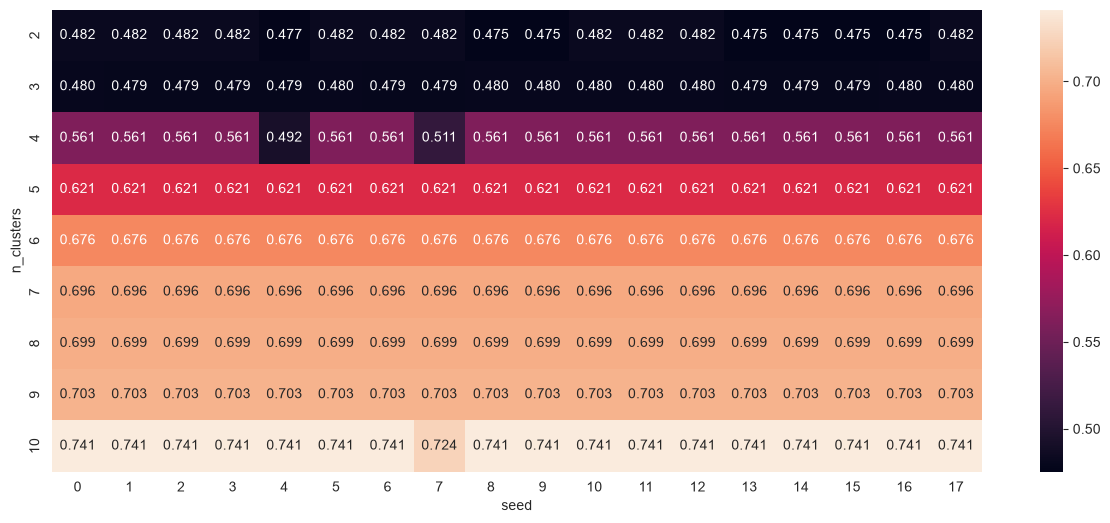

In [44]:
pivot= results_df.pivot_table(columns='seed',index='n_clusters', values='silhouette_score')

plt.figure(figsize=(15,6))
sns.heatmap(pivot, annot=True, fmt='.3f')

Based on the comparison between the elbow method and the silhouette score, choosing 5 or 6 clusters is the optimal choice.

# Clustering

In [47]:
k=6
kmeans_6 = KMeans(n_clusters=k, random_state=42, init='k-means++', n_init=10)
labels_6 = kmeans_6.fit_predict(X_pca)

print(f'Silhouette {k} cluster : {silhouette_score(X_pca,labels_6)}')
print('\nCustomer per cluster :')
print(pd.Series(labels_6).value_counts().sort_index())

Silhouette 6 cluster : 0.6756351329404817

Customer per cluster :
0    519
1    306
2    257
3    178
4    430
5    310
Name: count, dtype: int64


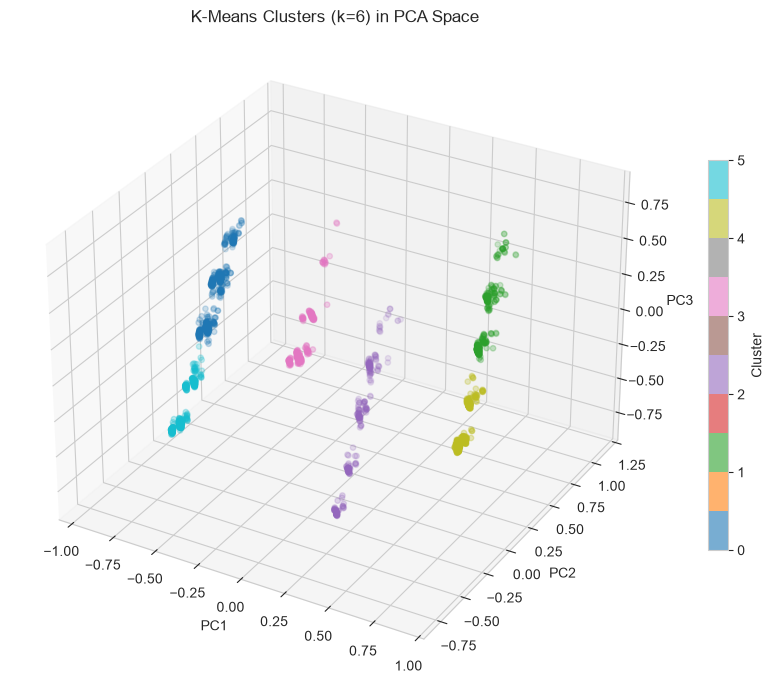

In [49]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    X_pca[:, 0], X_pca[:, 1], X_pca[:, 2],
    c=labels_6, cmap='tab10', alpha=0.6, s=15
)
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
ax.set_title(f'K-Means Clusters (k={k}) in PCA Space')
plt.colorbar(scatter, label='Cluster', shrink=0.6)
plt.tight_layout()
plt.show()

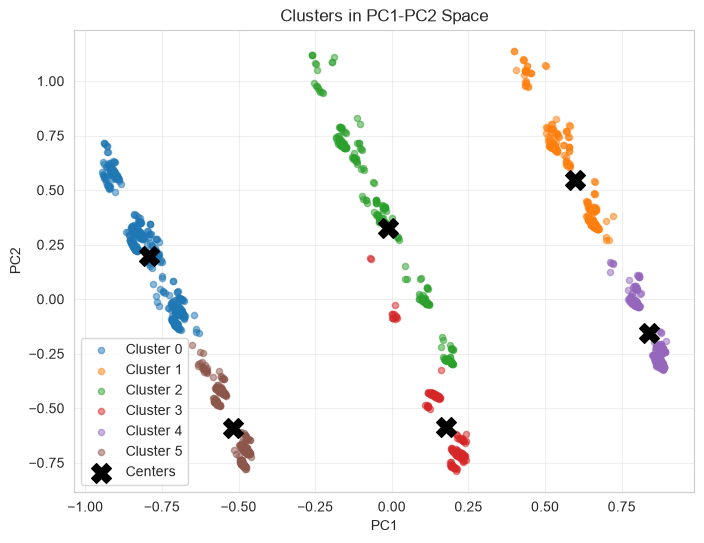

In [51]:
plt.figure(figsize=(8, 6))
for label in range(k):
    mask = labels_6 == label
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], label=f'Cluster {label}', alpha=0.5, s=20)

# Plot cluster centers
centers = kmeans_6.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='black', marker='X', s=200, label='Centers')

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Clusters in PC1-PC2 Space')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [52]:
results_6 = customer_info.copy()
results_6['Cluster'] = labels_6

# Profile each cluster by its average feature values
cluster_profile = results_6.groupby('Cluster').mean().round(2)
cluster_profile['Count'] = results_6.groupby('Cluster').size()
print('Cluster Profiles (mean feature values):')
cluster_profile

Cluster Profiles (mean feature values):


,Sex,Marital status,Age,Education,Income,Occupation,Settlement size,Count
Cluster,,,,,,,,
0,0.0,0.0,39.99,0.82,145373.26,1.27,1.52,519
1,1.0,1.0,34.28,1.33,136536.70,1.18,1.35,306
2,0.0,1.0,33.97,1.27,122976.72,0.93,0.92,257
3,1.0,0.0,35.15,0.93,97997.24,0.37,0.07,178
4,1.0,1.0,32.42,1.21,102142.33,0.43,0.01,430
5,0.0,0.0,37.56,0.74,102290.82,0.35,0.06,310


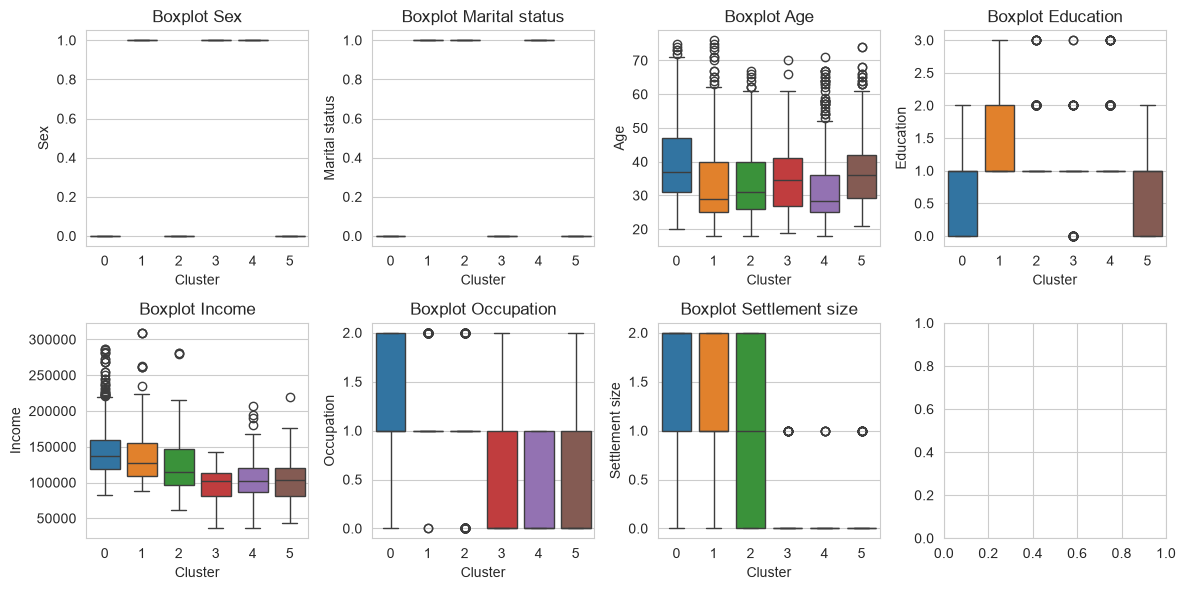

In [65]:
fig,ax = plt.subplots(2,4,figsize=(12,6))
ax = ax.flatten()

for i,col in enumerate(customer_info.columns):
    sns.boxplot(data=results_6,x='Cluster',y=col, ax=ax[i], palette='tab10')
    ax[i].set_title(f'Boxplot {col}')
    
plt.tight_layout()

### Label the Clusters

**What to do:** Based on the profile table and your boxplots above, fill in this table. Give each cluster a descriptive name that a marketing team would understand.

| Cluster | Descriptive Label | Key Characteristics (2–4 distinguishing features) |
|---------|------------------|----------------------------------------------------|
| 0 | Carrer Men  | Laki-laki, single, berpenghasilan sekitar 140 rb , tinggal di kota besar| 
| 1 | Married Girl | Perempuan, Menikah , berpenghasilam sekitar 136 rb, tinggal di kota besar | 
| 2 | Married Men | Laki Laki, Menikah, berpenghasilan sekitar 122 rb , tidnggal di kota kecil |
| 3 | Lower Class Singel Woman | Perempuan single berusaia 35 tahun, tinggal di kota kecil 90 rb|
| 4 | Middle Class Married Woman| Perempuan menikah berusia 32 tahun, tinggal di kota menengah dan berpengasilan 100 rb|
| 5 | Lower Class Carrer Men | Laki laki singel berusia 37 tahun, tinggal di kota kecil dan berpenghasilan 100 rb|

**Tips:**
- Focus on what makes each cluster **different** from the others
- Compare each cluster's mean Age, Income, Education, Occupation to the overall dataset mean
- Think about what a marketing team would call this group (e.g., "Young Urban Professionals", "Budget-Conscious Families")

In [97]:
results_6
X= results_6.drop(columns='Cluster')
y= results_6['Cluster']

print(X.shape,y.shape)


(2000, 7) (2000,)


# Build Clasifier Model

### Random Forest

In [98]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2, random_state=42, stratify=y)

print(f'Training Set : {X_train.shape[0]} Sampel')
print(f'Test Set : {X_test.shape[0]} Sampel')

Training Set : 1600 Sampel
Test Set : 400 Sampel


In [102]:
rf_model = RandomForestClassifier(n_estimators=100,max_depth=6,random_state=42)

rf_model.fit(X_train,y_train)
rf_pred = rf_model.predict(X_test)

print("Random Forest")
print(classification_report(y_test,rf_pred))
print(confusion_matrix(y_test,rf_pred))

Random Forest
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       104
           1       1.00      1.00      1.00        61
           2       1.00      1.00      1.00        51
           3       1.00      1.00      1.00        36
           4       1.00      1.00      1.00        86
           5       1.00      1.00      1.00        62

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400

[[104   0   0   0   0   0]
 [  0  61   0   0   0   0]
 [  0   0  51   0   0   0]
 [  0   0   0  36   0   0]
 [  0   0   0   0  86   0]
 [  0   0   0   0   0  62]]


### Gradient Boosting Classifier

In [100]:
gb_model = GradientBoostingClassifier(n_estimators=100,max_depth=4,random_state=42)
gb_model.fit(X_train,y_train)

gb_pred = gb_model.predict(X_test)

print('Gradient Boosting')
print(classification_report(gb_pred,y_test))
print(confusion_matrix(gb_pred,y_test))

Gradient Boosting
              precision    recall  f1-score   support

           0       1.00      0.99      1.00       105
           1       1.00      1.00      1.00        61
           2       1.00      1.00      1.00        51
           3       1.00      1.00      1.00        36
           4       1.00      1.00      1.00        86
           5       0.98      1.00      0.99        61

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400

[[104   0   0   0   0   1]
 [  0  61   0   0   0   0]
 [  0   0  51   0   0   0]
 [  0   0   0  36   0   0]
 [  0   0   0   0  86   0]
 [  0   0   0   0   0  61]]


**Random Forest sedikit unggul (0 kesalahan vs 1 kesalahan), tapi selisihnya tidak signifikan. Yang lebih perlu dicek adalah kenapa hasilnya bisa sesempurna itu.**

**Although the classification model achieves exceptionally high accuracy (close to 100%), this metric does not validate the quality of the K-Means clusters. This is expected because the cluster labels are derived deterministically from the input features via the K-Means algorithm, meaning the classifier essentially just replicates the mathematical boundaries established by K-Means.**

### Feature importance

[Text(3, 0, '0.0262109'),
 Text(3, 0, '0.0280584'),
 Text(3, 0, '0.0507913'),
 Text(3, 0, '0.0639447'),
 Text(3, 0, '0.266062'),
 Text(3, 0, '0.279484'),
 Text(3, 0, '0.285449')]

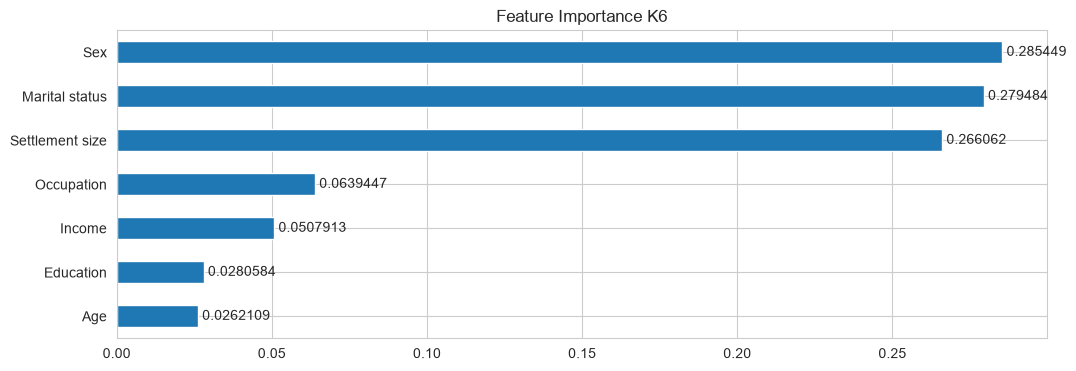

In [101]:
rf_featImp= pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(12,4))
ax = rf_featImp.plot(kind='barh')
plt.title('Feature Importance K6')
plt.bar_label(ax.containers[0], padding=3)

# Clustering K=5

In [55]:
k=5
kmeans_5 = KMeans(n_clusters=k,random_state=42,init='k-means++',n_init=10)
labels_5 = kmeans_5.fit_predict(X_pca)  

print(f'Silhouette {k} cluster : {silhouette_score(X_pca,labels_5)}')
print('\nCustomer per cluster :')
print(pd.Series(labels_5).value_counts().sort_index())

Silhouette 5 cluster : 0.6210661887664342

Customer per cluster :
0    310
1    736
2    519
3    257
4    178
Name: count, dtype: int64


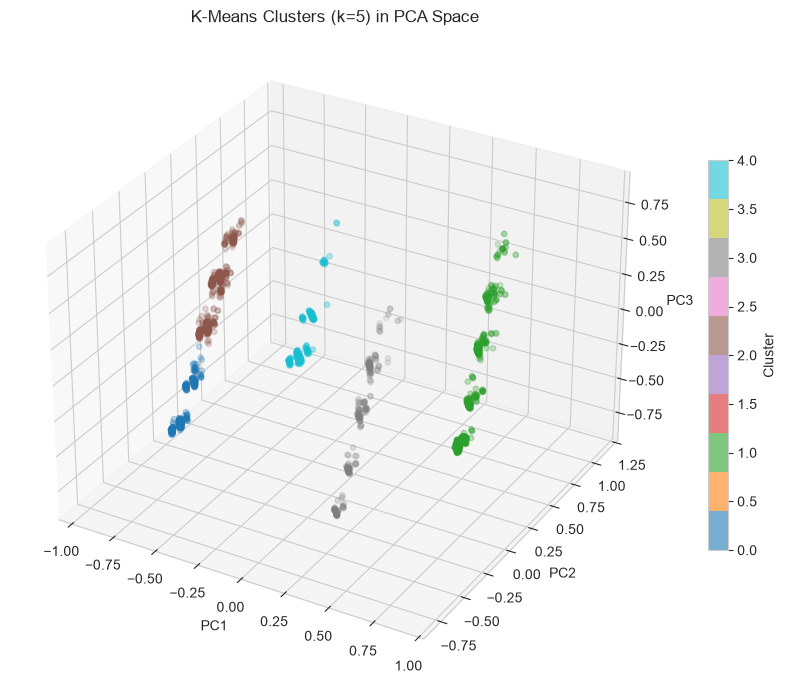

In [105]:
fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111,projection='3d')

scatter = ax.scatter(
    X_pca[:, 0], X_pca[:, 1], X_pca[:, 2],
    c=labels_5, cmap='tab10', alpha=0.6, s=15
)
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
ax.set_title(f'K-Means Clusters (k={k}) in PCA Space')
plt.colorbar(scatter, label='Cluster', shrink=0.6)
plt.tight_layout()
plt.show()

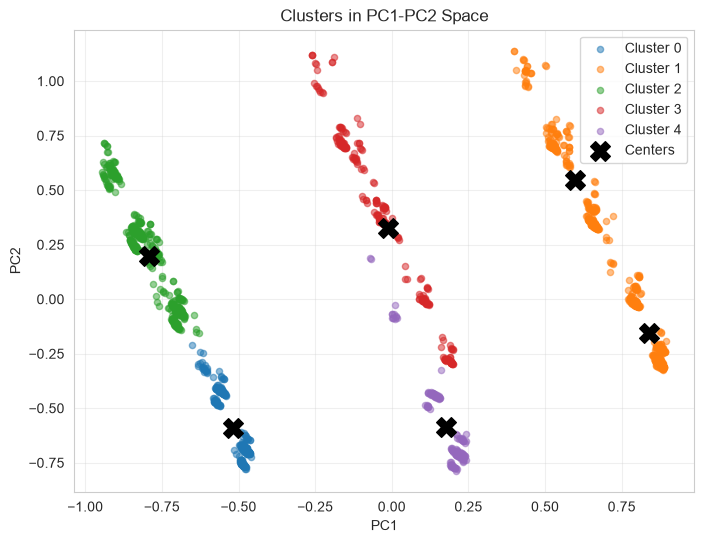

In [104]:
plt.figure(figsize=(8, 6))
for label in range(k):
    mask = labels_5 == label
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], label=f'Cluster {label}', alpha=0.5, s=20)

# Plot cluster centers
centers = kmeans_6.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='black', marker='X', s=200, label='Centers')

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Clusters in PC1-PC2 Space')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [58]:
results_5 = customer_info.copy()
results_5['Cluster'] = labels_5

# Profile each cluster by its average feature values
cluster_profile = results_5.groupby('Cluster').mean().round(2)
cluster_profile['Count'] = results_5.groupby('Cluster').size()
print('Cluster Profiles (mean feature values):')
cluster_profile

Cluster Profiles (mean feature values):


,Sex,Marital status,Age,Education,Income,Occupation,Settlement size,Count
Cluster,,,,,,,,
0,0.0,0.0,37.56,0.74,102290.82,0.35,0.06,310
1,1.0,1.0,33.19,1.26,116442.17,0.74,0.57,736
2,0.0,0.0,39.99,0.82,145373.26,1.27,1.52,519
3,0.0,1.0,33.97,1.27,122976.72,0.93,0.92,257
4,1.0,0.0,35.15,0.93,97997.24,0.37,0.07,178


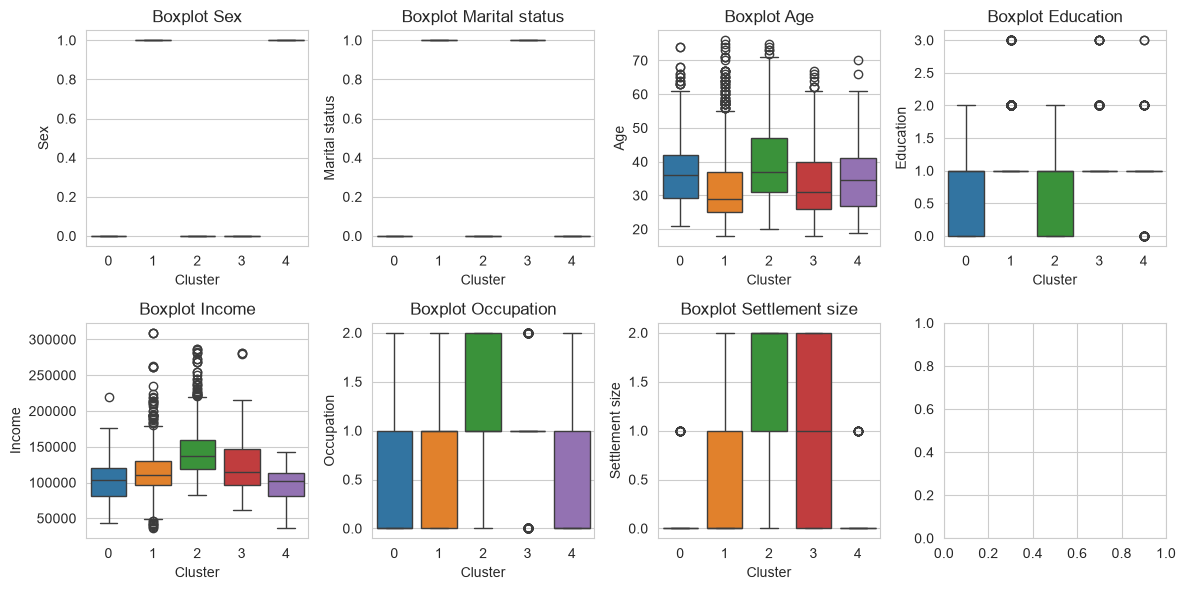

In [64]:
fig,ax = plt.subplots(2,4,figsize=(12,6))
ax = ax.flatten()

for i,col in enumerate(customer_info.columns):
    sns.boxplot(data=results_5,x='Cluster',y=col, ax=ax[i], palette='tab10')
    ax[i].set_title(f'Boxplot {col}')
    
plt.tight_layout()

### Label the 5 Clusters

| Cluster | Descriptive Label | Key Characteristics |
|---------|------------------|---------------------|
| 0 | Lower Singel Men | Laki laki singel berusia 37 tahun dengan rata rata income 102 rb|
| 1 | Lower Middle Married Woman | Perempuan menikah berusia 33 tahun dengan rata rata income 116 rb |
| 2 | Carrer Men | Laki laki singel berusisa 40 tahun dengan rata rata income 140 rb tinggal di kota besar|
| 3 | Middle Married Men | laki laki menikah berusia 33 tahun dengan rata rata income 122 rb tinggal di kota kecil hingga menengah|
| 4 | Lower Singel Woman| Perempuan singel berusia 35 tahun dengan rata rata income 90 rb tinggal di kota kecil |

**Which gives more useful segments, k=5 or k=6? Why?**



# Build Clasifier Model

In [92]:
results_5
X= results_5.drop(columns='Cluster')
y= results_5['Cluster']

print(X.shape,y.shape)


(2000, 7) (2000,)


In [93]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2, random_state=42, stratify=y)

print(f'Training Set : {X_train.shape[0]} Sampel')
print(f'Test Set : {X_test.shape[0]} Sampel')

Training Set : 1600 Sampel
Test Set : 400 Sampel


### Random Forest

In [103]:
rf_model = RandomForestClassifier(n_estimators=100,max_depth=6,random_state=42)

rf_model.fit(X_train,y_train)
rf_pred = rf_model.predict(X_test)

print("Random Forest")
print(classification_report(y_test,rf_pred))
print(confusion_matrix(y_test,rf_pred))

Random Forest
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       104
           1       1.00      1.00      1.00        61
           2       1.00      1.00      1.00        51
           3       1.00      1.00      1.00        36
           4       1.00      1.00      1.00        86
           5       1.00      1.00      1.00        62

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400

[[104   0   0   0   0   0]
 [  0  61   0   0   0   0]
 [  0   0  51   0   0   0]
 [  0   0   0  36   0   0]
 [  0   0   0   0  86   0]
 [  0   0   0   0   0  62]]


### Gradient Boosting Classifier

In [95]:
gb_model = GradientBoostingClassifier(n_estimators=100,max_depth=4,random_state=42)
gb_model.fit(X_train,y_train)

gb_pred = gb_model.predict(X_test)

print('Gradient Boosting')
print(classification_report(gb_pred,y_test))
print(confusion_matrix(gb_pred,y_test))

Gradient Boosting
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        62
           1       1.00      1.00      1.00       147
           2       1.00      1.00      1.00       104
           3       1.00      1.00      1.00        51
           4       1.00      1.00      1.00        36

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400

[[ 62   0   0   0   0]
 [  0 147   0   0   0]
 [  0   0 104   0   0]
 [  0   0   0  51   0]
 [  0   0   0   0  36]]


**Although the classification model achieves exceptionally high accuracy (close to 100%), this metric does not validate the quality of the K-Means clusters. This is expected because the cluster labels are derived deterministically from the input features via the K-Means algorithm, meaning the classifier essentially just replicates the mathematical boundaries established by K-Means.**


### Feature importance

[Text(3, 0, '0.0320266'),
 Text(3, 0, '0.0354181'),
 Text(3, 0, '0.0363006'),
 Text(3, 0, '0.0523089'),
 Text(3, 0, '0.14469'),
 Text(3, 0, '0.348745'),
 Text(3, 0, '0.350511')]

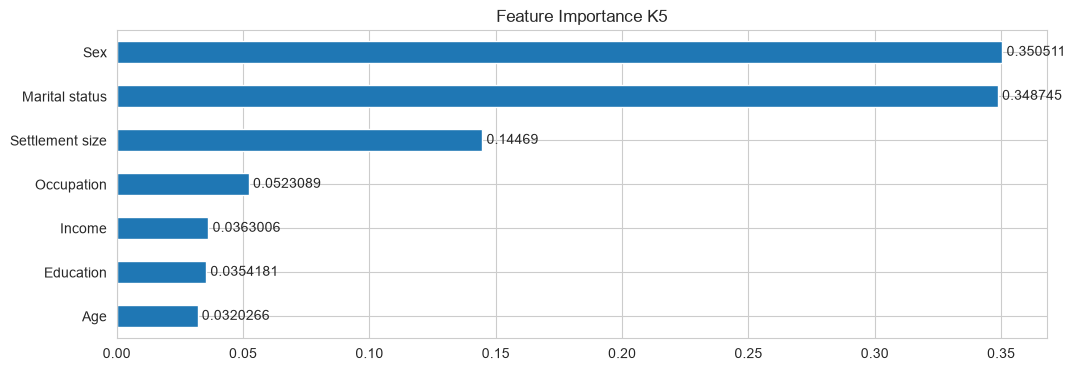

In [96]:
rf_featImp= pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(12,4))
ax = rf_featImp.plot(kind='barh')
plt.title('Feature Importance K5')
plt.bar_label(ax.containers[0], padding=3)

**Conclusion**

Based on the silhouette scores, both $k=6$ and $k=5$ show stable clustering results, but the score for $k=6$ is higher than $k=5$. Since silhouette scores closer to $1$ indicate denser and clearer separation between clusters, $k=6$ provides a better-defined grouping.Additionally, looking at the comparative scatter plots above, setting $k=5$ forces one of the clusters to merge unnaturally. Therefore, $k=6$ is the more effective and optimal choice for separating customer segments in this dataset.